# 07 · Anomaly detection: unusual collisions and unusual days

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryam843/uk-road-accident-analytics/blob/main/notebooks/07_anomalies.ipynb)

**Rebuilds** the original data-mining project's Isolation Forest (one-hot + PCA, contamination
0.02), dense autoencoder, Local Outlier Factor and z-score/IQR outliers, without its bugs:

| Original bug | Here |
|---|---|
| Autoencoder trained on scaled data but scored on unscaled data | reconstruction error computed on the same preprocessed matrix the model was trained on |
| IF output in {-1, 1} compared directly with AE output in {0, 1} | every detector converted explicitly to a {0, 1} anomaly flag before any comparison |
| Imputed zero coordinates | only collisions with valid coordinates (`coord_valid`); nothing imputed |
| "Anomalies" that were just rare categories | category profile and rarity of flagged rows reported |
| No evaluation | KSI enrichment with bootstrap CIs, top-20 inspection, and a daily-profile variant |

**Data:** stratified (year × KSI) sample of 200,000 collisions 2015-2019 with valid
coordinates, split 150,000 for fitting and 50,000 held out. Encoder, scaler, PCA, Isolation
Forest and autoencoder are fitted on the 150,000 only; every detector is evaluated on the
same 50,000 held-out collisions (LOF is fitted on them, as `novelty=False` requires).
The KSI label is never an input; it is only used to evaluate.

**Results (this run):** 
- The detectors barely agree. At contamination 0.02, Isolation Forest and the autoencoder
  share 198 of their roughly 1,000 flags each (Jaccard 0.113), LOF shares 0 with Isolation
  Forest and 2 with the autoencoder, and no row is flagged by all three. Spearman correlation of
  the scores is 0.39-0.56.
- **Flagged collisions are not reliably more severe.** KSI enrichment at 0.02: Isolation Forest
  1.17 (95% CI 1.03-1.31), LOF 1.11 (0.97-1.26), autoencoder **0.70** (0.59-0.80). The
  autoencoder mostly flags records with "Missing" or "Unknown" categories (38.8% of its flags
  contain a category seen in under 1% of collisions, vs 3.0% overall).
- The daily variant is more meaningful: all 10 most anomalous days 2005-2019 are snow or ice
  days (for example 2018-03-18 and 2018-02-28, 2010-12-18/19, 2013-01-20), with fewer
  collisions than usual and a lower KSI share on flagged days (0.1384 vs 0.1580).

In [1]:
# Setup: works from the repo root, from notebooks/, or on Google Colab.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/config.py").exists():
    if not Path("uk-road-accident-analytics").exists():
        !git clone -q https://github.com/maryam843/uk-road-accident-analytics.git
    %cd uk-road-accident-analytics
    %pip install -q -r requirements.txt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import clean, config, evaluate

config.setup_logging(logging.INFO)
evaluate.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = config.get_data_dir()
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
if not (PROCESSED / config.COLLISIONS_PARQUET).exists():
    # Fresh runtime (e.g. Colab): download (several GB) and clean. Takes a while, once.
    from src import download

    download.main([])
    clean.run()
print("DATA_DIR =", config.display_path(DATA_DIR))

import os
import time
import warnings

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")  # silence C++ info/warning/error logs
import keras
import tensorflow as tf
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

from src import features

CAT = ["road_type", "light", "weather", "surface", "junction", "urban_rural", "day_type"]
NUM = ["number_of_vehicles", "speed_limit", "hour"]
CONTAMINATIONS = [0.01, 0.02, 0.05]
MAIN_C = 0.02  # the original project's setting

DATA_DIR = data


I0000 00:00:1791056262.786344   15225 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791056264.557104   15225 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Data: sample, split and preprocessing

In [3]:
SRC = ["collision_index", "collision_year", "date", "hour", "speed_limit", "number_of_vehicles",
       "coord_valid", "ksi", *features.CONTEXT_SOURCES.values()]
coll = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET, columns=SRC)
coll = coll[coll["collision_year"].between(2015, 2019)]
print(f"2015-2019: {len(coll):,} collisions; {int((~coll['coord_valid']).sum()):,} without valid "
      "coordinates excluded")
coll = coll[coll["coord_valid"]].reset_index(drop=True)
strata = coll["collision_year"].astype(str) + "_" + coll["ksi"].astype(str)
idx, _ = train_test_split(coll.index, train_size=200_000, stratify=strata, random_state=config.RANDOM_STATE)
sample = coll.loc[np.sort(idx)].reset_index(drop=True)
frame = features.context_frame(sample)[CAT]
for col in NUM:
    frame[col] = sample[col].astype("float64")
frame["ksi"] = sample["ksi"].astype(int)
fit_df, test_df = train_test_split(frame, test_size=50_000, stratify=sample["collision_year"].astype(str)
                                   + "_" + frame["ksi"].astype(str), random_state=config.RANDOM_STATE)
y_test = test_df["ksi"].to_numpy()
print(f"sample {len(frame):,}: fit {len(fit_df):,}, held-out test {len(test_df):,}; "
      f"KSI share fit {fit_df['ksi'].mean():.4f}, test {y_test.mean():.4f}")
print("missing numeric values (imputed with the fit-set median):", frame[NUM].isna().sum().to_dict())

pre = features.make_preprocessor(CAT, NUM, min_frequency=1)  # keep every category explicit
X_fit = pre.fit_transform(fit_df[CAT + NUM]).toarray()
X_test = pre.transform(test_df[CAT + NUM]).toarray()
names = features.check_feature_coverage(pre, CAT, NUM)
num_idx = [names.index(f"num__{c}") for c in NUM]
print(f"{len(CAT)} categorical + {len(NUM)} numeric -> {X_fit.shape[1]} columns")
print("numeric columns after scaling, mean (fit / test):",
      np.round(X_fit[:, num_idx].mean(axis=0), 3).tolist(), "/", np.round(X_test[:, num_idx].mean(axis=0), 3).tolist())

2015-2019: 646,830 collisions; 136 without valid coordinates excluded


sample 200,000: fit 150,000, held-out test 50,000; KSI share fit 0.1825, test 0.1826
missing numeric values (imputed with the fit-set median): {'number_of_vehicles': 0, 'speed_limit': 42, 'hour': 0}


7 categorical + 3 numeric -> 45 columns
numeric columns after scaling, mean (fit / test): [-0.0, 0.0, -0.0] / [0.003, 0.001, 0.006]


## PCA
PCA is fitted on the fit set. The number of components that explains 95% of the variance is
kept and used as the input to Isolation Forest and LOF (as in the original project, but chosen
by explained variance instead of fixed at 20).

explained variance, first 10 components: [0.225, 0.167, 0.157, 0.085, 0.061, 0.051, 0.05, 0.042, 0.031, 0.023]
15 of 45 components explain 0.953 of the variance (20 components: 0.975)


19:37:48 INFO src.evaluate: Saved figure reports/figures/07_pca_variance.png


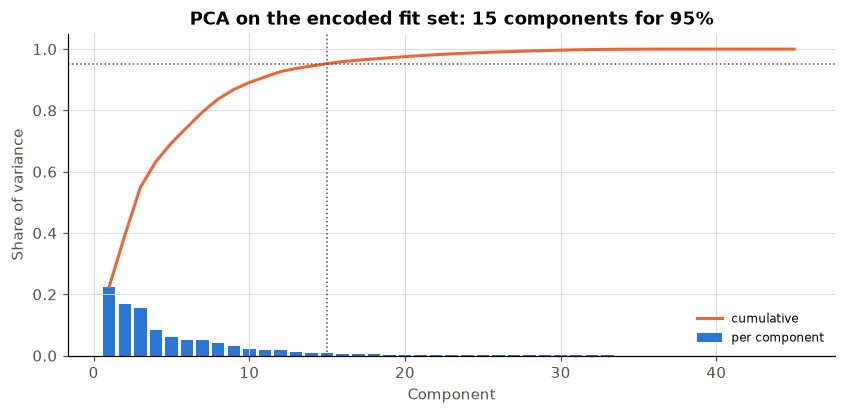

In [4]:
pca_full = PCA(random_state=config.RANDOM_STATE).fit(X_fit)
cum = np.cumsum(pca_full.explained_variance_ratio_)
N95 = int(np.searchsorted(cum, 0.95) + 1)
print("explained variance, first 10 components:", np.round(pca_full.explained_variance_ratio_[:10], 3).tolist())
print(f"{N95} of {X_fit.shape[1]} components explain {cum[N95 - 1]:.3f} of the variance "
      f"(20 components: {cum[19]:.3f})")
pca = PCA(n_components=N95, random_state=config.RANDOM_STATE).fit(X_fit)
Z_fit, Z_test = pca.transform(X_fit), pca.transform(X_test)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_, color=evaluate.PALETTE[0], label="per component")
ax.plot(range(1, len(cum) + 1), cum, color=evaluate.PALETTE[1], label="cumulative")
ax.axhline(0.95, color="#52514e", linestyle=":", linewidth=1)
ax.axvline(N95, color="#52514e", linestyle=":", linewidth=1)
ax.set_xlabel("Component")
ax.set_ylabel("Share of variance")
ax.set_title(f"PCA on the encoded fit set: {N95} components for 95%")
ax.legend(fontsize=8)
evaluate.save_fig(fig, "07_pca_variance")
plt.show()

## Isolation Forest on the PCA output
`IsolationForest.predict` returns -1 for an anomaly and 1 for a normal row; it is converted
explicitly to a flag (1 = anomaly, 0 = normal). The anomaly score is `-score_samples`
(higher = more anomalous), which does not depend on the contamination setting.

In [5]:
flags = {c: {} for c in CONTAMINATIONS}
if_rows = []
for c in CONTAMINATIONS:
    iso = IsolationForest(n_estimators=300, contamination=c, random_state=config.RANDOM_STATE, n_jobs=-1)
    iso.fit(Z_fit)
    pred = iso.predict(Z_test)                       # {-1, 1}
    flags[c]["Isolation Forest"] = (pred == -1).astype(int)   # -> {0, 1}
    if_rows.append({"contamination": c, "fit_rows_flagged": int((iso.predict(Z_fit) == -1).sum()),
                    "test_rows_flagged": int(flags[c]["Isolation Forest"].sum()),
                    "test_flag_rate": flags[c]["Isolation Forest"].mean()})
    if c == MAIN_C:
        iso_main, iso_pred_main = iso, pred
scores = {"Isolation Forest": -iso_main.score_samples(Z_test)}
display(pd.DataFrame(if_rows).set_index("contamination").style.format({"test_flag_rate": "{:.4f}"}))

,fit_rows_flagged,test_rows_flagged,test_flag_rate
contamination,,,
0.010000,1500,493,0.0099
0.020000,3000,970,0.0194
0.050000,7500,2488,0.0498


## Dense autoencoder (input-32-8-32-output)
Trained on the fit set's preprocessed matrix (one-hot columns plus standardised numerics), with
10% of it held back for early stopping (stop when validation MSE has not improved by at least
1e-5 for 10 epochs; the best weights are kept). The reconstruction error is computed on **exactly the
same kind of matrix** (`pre.transform`, the same fitted scaler), never on raw values. The
threshold for contamination c is the (1 - c) quantile of the fit-set error.

In [6]:
keras.utils.set_random_seed(config.RANDOM_STATE)
tf.config.experimental.enable_op_determinism()
d = X_fit.shape[1]
ae = keras.Sequential([keras.Input(shape=(d,)), keras.layers.Dense(32, activation="relu"),
                       keras.layers.Dense(8, activation="relu"), keras.layers.Dense(32, activation="relu"),
                       keras.layers.Dense(d, activation="linear")])
ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
t0 = time.time()
hist = ae.fit(X_fit, X_fit, epochs=1000, batch_size=512, validation_split=0.1, shuffle=True, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=10, min_delta=1e-5, restore_best_weights=True)])
print(f"stopped after {len(hist.history['loss'])} of 1000 epochs ({time.time() - t0:.0f} s): no validation-MSE "
      f"improvement of 1e-5 for 10 epochs; lowest validation MSE {min(hist.history['val_loss']):.4f}")


def recon_error(model, X):
    return np.mean((X - model.predict(X, batch_size=4096, verbose=0)) ** 2, axis=1)


err_fit, err_test = recon_error(ae, X_fit), recon_error(ae, X_test)
scores["Autoencoder"] = err_test
for c in CONTAMINATIONS:
    thr = np.quantile(err_fit, 1 - c)
    flags[c]["Autoencoder"] = (err_test > thr).astype(int)
print("test rows flagged:", {c: int(flags[c]["Autoencoder"].sum()) for c in CONTAMINATIONS})

stopped after 299 of 1000 epochs (204 s): no validation-MSE improvement of 1e-5 for 10 epochs; lowest validation MSE 0.0117


test rows flagged: {0.01: 508, 0.02: 975, 0.05: 2498}


**What the original scaling bug does.** The same trained autoencoder is scored on a matrix
whose numeric columns are left unscaled (raw vehicles, mph and hour). The flags then say
almost nothing about unusual collisions; they mostly pick out large raw numbers.

In [7]:
X_test_unscaled = X_test.copy()
X_test_unscaled[:, num_idx] = test_df[NUM].fillna(fit_df[NUM].median()).to_numpy()
err_bug = recon_error(ae, X_test_unscaled)
flag_bug = (err_bug > np.quantile(err_bug, 1 - MAIN_C)).astype(int)
print(f"Jaccard(correct AE flags, unscaled-scoring flags) at c={MAIN_C}: "
      f"{evaluate.jaccard(flags[MAIN_C]['Autoencoder'], flag_bug):.3f}")
print("mean speed limit: all test rows "
      f"{test_df['speed_limit'].mean():.1f} mph, flagged by correct AE "
      f"{test_df['speed_limit'][flags[MAIN_C]['Autoencoder'] == 1].mean():.1f}, flagged by buggy scoring "
      f"{test_df['speed_limit'][flag_bug == 1].mean():.1f}")

Jaccard(correct AE flags, unscaled-scoring flags) at c=0.02: 0.007
mean speed limit: all test rows 37.5 mph, flagged by correct AE 35.3, flagged by buggy scoring 70.0


## Local Outlier Factor (novelty=False) on the 50,000 held-out rows
LOF compares each row's local density with its neighbours' and, with `novelty=False`, scores
the rows it was fitted on, so it is fitted directly on the held-out PCA matrix. Mostly
categorical data contains many identical rows, which LOF handles badly (identical neighbours
have zero distance); the share is printed.

In [8]:
_, inverse, dup_counts = np.unique(np.round(Z_test, 8), axis=0, return_inverse=True, return_counts=True)
print(f"held-out rows identical to at least one other row: {(dup_counts[inverse.ravel()] > 1).mean():.1%}")
for c in CONTAMINATIONS:
    lof = LocalOutlierFactor(n_neighbors=20, contamination=c, novelty=False, n_jobs=-1)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        pred = lof.fit_predict(Z_test)              # {-1, 1}
    flags[c]["LOF"] = (pred == -1).astype(int)       # -> {0, 1}
    if c == MAIN_C:
        scores["LOF"] = -lof.negative_outlier_factor_
        if caught:
            print("sklearn warning:", str(caught[0].message)[:160])
print("test rows flagged:", {c: int(flags[c]["LOF"].sum()) for c in CONTAMINATIONS})

held-out rows identical to at least one other row: 74.0%


sklearn warning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.


test rows flagged: {0.01: 499, 0.02: 986, 0.05: 2500}


## Agreement between detectors
All outputs are {0, 1} flags (asserted below). For each pair: rows flagged by both, Jaccard
index, and the Spearman correlation of the continuous anomaly scores (contamination-free).
The last line repeats the original project's comparison, which matched IF's raw {-1, 1}
output against the autoencoder's {0, 1} flags.

In [9]:
DETECTORS = ["Isolation Forest", "Autoencoder", "LOF"]
for c in CONTAMINATIONS:
    for name in DETECTORS:
        assert set(np.unique(flags[c][name])) <= {0, 1}, name
pairs = [("Isolation Forest", "Autoencoder"), ("Isolation Forest", "LOF"), ("Autoencoder", "LOF")]
agree_rows = []
for c in CONTAMINATIONS:
    for a, b in pairs:
        fa, fb = flags[c][a], flags[c][b]
        agree_rows.append({"contamination": c, "pair": f"{a} vs {b}", "flagged_a": int(fa.sum()),
                           "flagged_b": int(fb.sum()), "both": int((fa & fb).sum()),
                           "jaccard": evaluate.jaccard(fa, fb)})
    agree_rows.append({"contamination": c, "pair": "all three", "both": int(np.prod([flags[c][n] for n in DETECTORS],
                                                                                     axis=0).sum())})
agreement = pd.DataFrame(agree_rows).set_index(["contamination", "pair"])
display(agreement.style.format({"jaccard": "{:.3f}", "flagged_a": "{:,.0f}", "flagged_b": "{:,.0f}",
                                "both": "{:,.0f}"}, na_rep=""))
rho = pd.DataFrame({f"{a} vs {b}": [spearmanr(scores[a], scores[b]).statistic] for a, b in pairs},
                   index=["Spearman rho of scores"])
display(rho.style.format("{:.3f}"))
buggy = (iso_pred_main == flags[MAIN_C]["Autoencoder"]).mean()
print(f"Original-style 'agreement' (IF raw -1/1 == AE 0/1) at c={MAIN_C}: {buggy:.1%} of rows. "
      f"It counts IF 'normal' (1) == AE 'anomaly' (1) as agreement; the correct overlap is "
      f"{int((flags[MAIN_C]['Isolation Forest'] & flags[MAIN_C]['Autoencoder']).sum())} rows.")

,Isolation Forest vs Autoencoder,Isolation Forest vs LOF,Autoencoder vs LOF
Spearman rho of scores,0.561,0.403,0.393


Original-style 'agreement' (IF raw -1/1 == AE 0/1) at c=0.02: 1.6% of rows. It counts IF 'normal' (1) == AE 'anomaly' (1) as agreement; the correct overlap is 198 rows.


## Evaluation without labels: are flagged collisions more severe?
**KSI enrichment** = KSI share among flagged rows / KSI share among all held-out rows; 1 means
flagged collisions are no more severe than average. 95% CIs from 1,000 bootstrap resamples of
the held-out rows (flags fixed).

In [10]:
BASE = y_test.mean()
enr_rows = []
for c in CONTAMINATIONS:
    for name in DETECTORS:
        f = flags[c][name]
        ratio, lo, hi = evaluate.bootstrap_enrichment(y_test, f, n_boot=1000, seed=config.RANDOM_STATE)
        enr_rows.append({"contamination": c, "detector": name, "flagged": int(f.sum()),
                         "ksi_share_flagged": y_test[f == 1].mean(), "enrichment": ratio, "ci_low": lo,
                         "ci_high": hi})
enrichment = pd.DataFrame(enr_rows).set_index(["contamination", "detector"])
print(f"KSI share, all held-out rows: {BASE:.4f}")
display(enrichment.style.format({"ksi_share_flagged": "{:.4f}", "enrichment": "{:.2f}", "ci_low": "{:.2f}",
                                 "ci_high": "{:.2f}"}))

KSI share, all held-out rows: 0.1826


In [11]:
fit_freq = {col: fit_df[col].value_counts(normalize=True) for col in CAT}
rarity = pd.DataFrame({col: test_df[col].map(fit_freq[col]).fillna(0).to_numpy() for col in CAT})
min_freq = rarity.min(axis=1).to_numpy()
prof_rows = []
for name in DETECTORS:
    f = flags[MAIN_C][name] == 1
    prof_rows.append({"detector": name, "flagged": int(f.sum()),
                      "has_category_under_1pct": (min_freq[f] < 0.01).mean(),
                      "median_rarest_category_share": np.median(min_freq[f]),
                      "mean_vehicles": test_df["number_of_vehicles"][f].mean(),
                      "mean_speed_limit": test_df["speed_limit"][f].mean()})
prof_rows.append({"detector": "all held-out rows", "flagged": len(test_df),
                  "has_category_under_1pct": (min_freq < 0.01).mean(),
                  "median_rarest_category_share": np.median(min_freq),
                  "mean_vehicles": test_df["number_of_vehicles"].mean(),
                  "mean_speed_limit": test_df["speed_limit"].mean()})
print(f"Profile of flagged rows at contamination {MAIN_C} (category shares from the fit set):")
display(pd.DataFrame(prof_rows).set_index("detector").style.format(
    {"has_category_under_1pct": "{:.1%}", "median_rarest_category_share": "{:.3f}",
     "mean_vehicles": "{:.2f}", "mean_speed_limit": "{:.1f}"}))
lift_rows = []
for name in DETECTORS:
    f = flags[MAIN_C][name] == 1
    for col in CAT:
        share_f = test_df.loc[f, col].value_counts(normalize=True)
        share_all = test_df[col].value_counts(normalize=True)
        for cat, sh in share_f.items():
            if sh >= 0.10:
                lift_rows.append({"detector": name, "feature": col, "category": cat, "share_flagged": sh,
                                  "share_all": share_all[cat], "lift": sh / share_all[cat]})
lifts = pd.DataFrame(lift_rows).sort_values("lift", ascending=False).groupby("detector").head(5)
print("Most over-represented categories among flagged rows (share among flagged >= 10%):")
display(lifts.set_index(["detector", "feature"]).style.format(
    {"share_flagged": "{:.1%}", "share_all": "{:.1%}", "lift": "{:.1f}"}))

Profile of flagged rows at contamination 0.02 (category shares from the fit set):


,flagged,has_category_under_1pct,median_rarest_category_share,mean_vehicles,mean_speed_limit
detector,,,,,
Isolation Forest,970,10.7%,0.033,2.32,48.8
Autoencoder,975,38.8%,0.012,1.69,35.3
LOF,986,4.9%,0.112,1.75,34.8
all held-out rows,50000,3.0%,0.152,1.84,37.5


Most over-represented categories among flagged rows (share among flagged >= 10%):


In [12]:
ranks = pd.DataFrame({n: pd.Series(scores[n]).rank(ascending=False).to_numpy() for n in DETECTORS})
top20 = test_df.assign(**{f"rank_{n.split()[0]}": ranks[n].to_numpy() for n in DETECTORS},
                       mean_rank=ranks.mean(axis=1).to_numpy()).nsmallest(20, "mean_rank")
print("Top 20 held-out collisions by mean rank across the three detectors (rank 1 = most anomalous):")
display(top20.drop(columns=["day_type"]).style.format({c: "{:,.0f}" for c in
        ["number_of_vehicles", "speed_limit", "hour", "rank_Isolation", "rank_Autoencoder", "rank_LOF", "mean_rank"]}))
print(f"KSI among these 20: {top20['ksi'].sum()} (expected at the base rate: {20 * BASE:.1f})")

Top 20 held-out collisions by mean rank across the three detectors (rank 1 = most anomalous):


,road_type,light,weather,surface,junction,urban_rural,number_of_vehicles,speed_limit,hour,ksi,rank_Isolation,rank_Autoencoder,rank_LOF,mean_rank
13700,Single carriageway,Darkness - no lighting,Other,Dry,Not at junction or within 20 metres,Urban,1,60,1,0,57,234,"2,650",980
91044,Dual carriageway,Darkness - lighting unknown,Unknown,Dry,Not at junction or within 20 metres,Rural,4,70,17,0,208,462,"2,839","1,170"
34122,Single carriageway,Darkness - lighting unknown,Other,Dry,Crossroads,Urban,2,30,7,0,"1,074",456,"2,722","1,417"
89164,Single carriageway,Darkness - no lighting,Fine no high winds,Dry,Not at junction or within 20 metres,Urban,1,60,22,0,"1,871","2,413",1,"1,428"
94844,Roundabout,Darkness - lighting unknown,Raining no high winds,Dry,Roundabout,Rural,2,30,16,1,"1,473",347,"2,660","1,493"
8567,Unknown,Daylight,Unknown,Dry,T or staggered junction,Rural,2,30,11,0,825,341,"3,418","1,528"
154330,Single carriageway,Darkness - no lighting,Fine + high winds,Dry,Not at junction or within 20 metres,Urban,2,60,18,1,"1,850",174,"2,613","1,546"
112230,Single carriageway,Darkness - lighting unknown,Unknown,Dry,Not at junction or within 20 metres,Urban,3,30,7,0,"1,603",474,"2,590","1,556"
136042,Single carriageway,Darkness - no lighting,Fine no high winds,Frost or ice,Not at junction or within 20 metres,Urban,1,60,22,0,"1,854",278,"2,816","1,649"
51628,Dual carriageway,Darkness - no lighting,Snowing no high winds,Frost or ice,Not at junction or within 20 metres,Rural,13,70,16,0,1,"1,202","3,788","1,664"


KSI among these 20: 3 (expected at the base rate: 3.7)


## z-score and IQR: data-validation checks on genuinely numeric columns

z-scores and IQR fences assume a continuous numeric variable. They are applied only to the
count columns (vehicles, casualties) of all 2015-2019 collisions, as **validation** checks: are
the extreme values plausible records or data errors? Speed limit (six legal values) and hour
(circular) are not continuous measurements, so they get range checks instead. Casualty counts
are outcomes and are used here only to validate the data, never as model inputs.

In [13]:
full = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET,
                       columns=["collision_year", "number_of_vehicles", "number_of_casualties", "speed_limit",
                                "hour", "coord_valid"])
full = full[full["collision_year"].between(2015, 2019)]
val_rows = []
for col in ["number_of_vehicles", "number_of_casualties"]:
    v = full[col].astype(float)
    z = (v - v.mean()) / v.std()
    q1, q3 = v.quantile([0.25, 0.75])
    iqr = q3 - q1
    val_rows.append({"column": col, "rows": int(v.notna().sum()), "min": v.min(), "zero_or_negative": int((v <= 0).sum()),
                     "mean": v.mean(), "median": v.median(),
                     "q1": q1, "q3": q3, "max": v.max(), "abs_z_over_3": int((z.abs() > 3).sum()),
                     "outside_iqr_fences": int(((v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)).sum())})
display(pd.DataFrame(val_rows).set_index("column").style.format(
    {"min": "{:.0f}", "mean": "{:.2f}", "median": "{:.0f}", "q1": "{:.0f}", "q3": "{:.0f}", "max": "{:.0f}",
     "abs_z_over_3": "{:,}", "outside_iqr_fences": "{:,}", "rows": "{:,}"}))
for col in ["number_of_vehicles", "number_of_casualties"]:
    top = full[col].value_counts().sort_index().tail(5)
    print(f"{col}: five largest values and their counts:", {int(k): int(n) for k, n in top.items()})
print(f"speed_limit outside 20/30/40/50/60/70 (set to missing in cleaning): {int(full['speed_limit'].isna().sum()):,}")
print(f"hour missing or outside 0-23: {int(full['hour'].isna().sum()):,}")
print(f"coordinates missing or outside GB: {int((~full['coord_valid']).sum()):,}")

,rows,min,zero_or_negative,mean,median,q1,q3,max,abs_z_over_3,outside_iqr_fences
column,,,,,,,,,,
number_of_vehicles,"646,830",1,0,1.84,2,1,2,37,"15,427","15,427"
number_of_casualties,"646,830",1,0,1.32,1,1,1,59,"15,233","137,440"


number_of_vehicles: five largest values and their counts: {17: 1, 18: 1, 23: 1, 24: 1, 37: 1}
number_of_casualties: five largest values and their counts: {38: 1, 42: 1, 52: 1, 58: 1, 59: 1}


speed_limit outside 20/30/40/50/60/70 (set to missing in cleaning): 120
hour missing or outside 0-23: 0
coordinates missing or outside GB: 136


## Daily-profile variant: anomalous days (from the scaffold plan)

Unit = one day, 2005-2019. Features describe the day's mix: collision count relative to that
year's average day, KSI share relative to that year's share (both remove the long-term fall in
collisions and the 2016+ severity reporting change), shares by hour band, darkness, wet and
icy/snowy surfaces, rain, snow and fog, and a weekend flag. Scaler and Isolation Forest are
fitted on 2005-2015 days only, then every day is scored. The top 10 days are listed with the
feature that deviates most (largest |z| under the training scaler).

In [14]:
DCOLS = ["date", "collision_year", "hour", "ksi", "light_conditions_label", "road_surface_conditions_label",
         "weather_conditions_label"]
dd = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET, columns=DCOLS).dropna(subset=["date"])
light = dd["light_conditions_label"].astype(str).str.lower()
surface = dd["road_surface_conditions_label"].astype(str).str.lower()
weather = dd["weather_conditions_label"].astype(str).str.lower()
dd = dd.assign(dark=light.str.contains("dark"), wet=surface.str.contains("wet"),
               ice_snow=surface.str.contains("snow|frost|ice"), rain=weather.str.contains("rain"),
               snow=weather.str.contains("snow"), fog=weather.str.contains("fog"),
               band=features.hour_band(dd["hour"]))
day = dd.groupby("date").agg(collisions=("ksi", "size"), ksi_share=("ksi", "mean"), dark=("dark", "mean"),
                             wet=("wet", "mean"), ice_snow=("ice_snow", "mean"), rain=("rain", "mean"),
                             snow=("snow", "mean"), fog=("fog", "mean"))
bands = pd.crosstab(dd["date"], dd["band"], normalize="index")
bands.columns = [f"share_{c.split()[0]}" for c in bands.columns]
day = day.join(bands)
year = day.index.year
day["count_ratio"] = day["collisions"] / day.groupby(year)["collisions"].transform("mean")
day["ksi_share_diff"] = day["ksi_share"] - day.groupby(year)["ksi_share"].transform("mean")
day["weekend"] = (day.index.dayofweek >= 5).astype(int)
DAY_FEATURES = ["count_ratio", "ksi_share_diff", "dark", "wet", "ice_snow", "rain", "snow", "fog", "weekend",
                *bands.columns]
train_days = day.index.year <= 2015
scaler = StandardScaler().fit(day.loc[train_days, DAY_FEATURES])
Zd = scaler.transform(day[DAY_FEATURES])
iso_d = IsolationForest(n_estimators=300, contamination=0.01, random_state=config.RANDOM_STATE)
iso_d.fit(Zd[train_days])
day["anomaly_score"] = -iso_d.score_samples(Zd)
day["flag"] = (iso_d.predict(Zd) == -1).astype(int)
zframe = pd.DataFrame(Zd, index=day.index, columns=DAY_FEATURES)
day["most_unusual"] = [f"{f} (z {zframe.loc[d, f]:+.1f})" for d, f in zframe.abs().idxmax(axis=1).items()]
print(f"{len(day):,} days; fitted on {train_days.sum():,} days (2005-2015); "
      f"flagged: {day.loc[train_days, 'flag'].sum()} training days, {day.loc[~train_days, 'flag'].sum()} days 2016-2019")
top10 = day.sort_values("anomaly_score", ascending=False).head(10)
display(top10[["collisions", "count_ratio", "ksi_share", "ice_snow", "snow", "fog", "dark", "weekend",
               "most_unusual"]].assign(weekday=top10.index.day_name())
        .set_axis(top10.index.strftime("%Y-%m-%d")).rename_axis("date").style.format(
    {"count_ratio": "{:.2f}", "ksi_share": "{:.3f}", "ice_snow": "{:.1%}", "snow": "{:.1%}", "fog": "{:.1%}",
     "dark": "{:.1%}"}))
flagged_days = day[day["flag"] == 1]
print(f"KSI share on flagged days {(flagged_days['ksi_share'] * flagged_days['collisions']).sum() / flagged_days['collisions'].sum():.4f} "
      f"vs all days {(day['ksi_share'] * day['collisions']).sum() / day['collisions'].sum():.4f}")
print("Most frequent 'most unusual' feature among flagged days:",
      flagged_days["most_unusual"].str.split(" ").str[0].value_counts().head(5).to_dict())

5,478 days; fitted on 4,017 days (2005-2015); flagged: 41 training days, 10 days 2016-2019


,collisions,count_ratio,ksi_share,ice_snow,snow,fog,dark,weekend,most_unusual,weekday
date,,,,,,,,,,
2018-03-18,207,0.62,0.140,60.9%,54.6%,0.5%,51.7%,1,snow (z +12.0),Sunday
2010-01-13,398,0.94,0.090,67.6%,40.2%,1.5%,39.2%,0,snow (z +8.8),Wednesday
2013-01-20,180,0.47,0.089,67.2%,53.9%,0.0%,53.3%,1,snow (z +11.9),Sunday
2012-02-05,238,0.60,0.151,60.9%,19.3%,5.5%,55.9%,1,ice_snow (z +6.4),Sunday
2010-12-19,231,0.55,0.074,77.1%,24.2%,2.6%,54.5%,1,ice_snow (z +8.2),Sunday
2009-12-25,202,0.45,0.168,55.4%,6.9%,2.5%,60.9%,0,ice_snow (z +5.8),Friday
2010-12-18,296,0.70,0.118,83.4%,40.2%,0.7%,49.0%,1,ice_snow (z +8.9),Saturday
2018-02-28,291,0.87,0.141,67.7%,56.0%,0.0%,19.2%,0,snow (z +12.4),Wednesday
2017-12-10,228,0.64,0.149,42.5%,30.3%,0.4%,57.0%,1,snow (z +6.6),Sunday


KSI share on flagged days 0.1384 vs all days 0.1580
Most frequent 'most unusual' feature among flagged days: {'snow': 23, 'ice_snow': 16, 'share_00-05': 7, 'share_20-23': 2, 'fog': 1}


## Conclusion


**Collision-level anomalies mean rare combinations, not danger.**
- Isolation Forest flags rare but real contexts: darkness without street lighting (40.2% of its
  flags vs 5.2% of all collisions), dual carriageways, rain, higher speed limits (mean 48.8 vs
  37.5 mph). These go with slightly more severe outcomes (enrichment 1.17 at contamination 0.02,
  CI 1.03-1.31), which is the same signal notebook 04 found with a supervised model, found much
  less efficiently.
- The autoencoder reconstructs common profiles well, so its largest errors are on rare or
  badly recorded categories ("Missing" surface, "Unknown" weather or road type). Its flags are
  **less** severe than average (enrichment 0.70, CI 0.59-0.80). It is a data-quality detector
  more than a risk detector.
- LOF is unreliable on this data: 74.0% of the held-out rows have an exact duplicate in feature
  space, so local densities are degenerate (scikit-learn warns about it), and its flags overlap
  with almost nothing else.
- The top 20 by mean rank contain 3 KSI collisions, against 3.7 expected at the base rate.
- **The original project's bugs change the answer completely.** Scoring the autoencoder on
  unscaled numerics flags a different set of rows (Jaccard 0.007 with the correct flags), all
  with a 70 mph limit (mean 70.0 vs 37.5). Comparing IF's raw {-1, 1} with the autoencoder's
  {0, 1} output "agrees" on 1.6% of rows by counting IF-normal = AE-anomaly as a match; the real
  overlap is 198 rows.
- **z-score / IQR are validation checks, not anomaly detection.** For vehicle counts the |z| > 3
  rule and the IQR fences both flag the 15,427 collisions with 4 or more vehicles; for casualty
  counts the IQR is 0 (Q1 = Q3 = 1), so the fences flag every collision with more than one
  casualty (137,440). No count is zero or negative, the maxima (37 vehicles, 59 casualties) are
  single records, and the cleaning log already set 120 invalid speed limits and 136 invalid
  coordinates aside. Nothing here looks like a data error that needs fixing.
- **Daily profiles are the more useful unit.** Fitted on 2005-2015 days only, Isolation Forest
  flags 41 training days and 10 days in 2016-2019, and all 10 top days are snow or ice days,
  usually with fewer collisions than a normal day. Days are interpretable and can be checked
  against the weather; single collisions flagged as "anomalous" mostly cannot.